# Model Building

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
import utils

In [2]:
df=pd.read_csv('data/reviews_cleaned.csv').dropna(subset=['clean_text','label'])
print('rows:',len(df),'| classes:',df['label'].nunique())

rows: 30000 | classes: 2


## TF-IDF features + train/test split

In [3]:
X_train,X_test,y_train,y_test=train_test_split(df['clean_text'],df['label'],test_size=0.2,random_state=42,stratify=df['label'])
vec=TfidfVectorizer(max_features=20000,ngram_range=(1,2),sublinear_tf=True)
Xtrain=vec.fit_transform(X_train); Xtest=vec.transform(X_test)
print('TF-IDF:',Xtrain.shape)

TF-IDF: (24000, 20000)


In [4]:
## Train & compare six classifiers

In [5]:
results=[]
for name,model in utils.get_models().items():
    model.fit(Xtrain,y_train); pred=model.predict(Xtest)
    results.append(utils.evaluate_model(name,y_test,pred))
res_df=utils.compare_models(results)
res_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8913,0.8913,0.8913,0.8913
1,Ridge Classifier,0.8852,0.8852,0.8852,0.8852
2,Complement NB,0.8825,0.8825,0.8825,0.8825
3,Multinomial NB,0.8825,0.8825,0.8825,0.8825
4,Linear SVM,0.8800,0.8800,0.8800,0.8800
5,Passive Aggressive,0.8558,0.8558,0.8558,0.8558


## Comparison chart

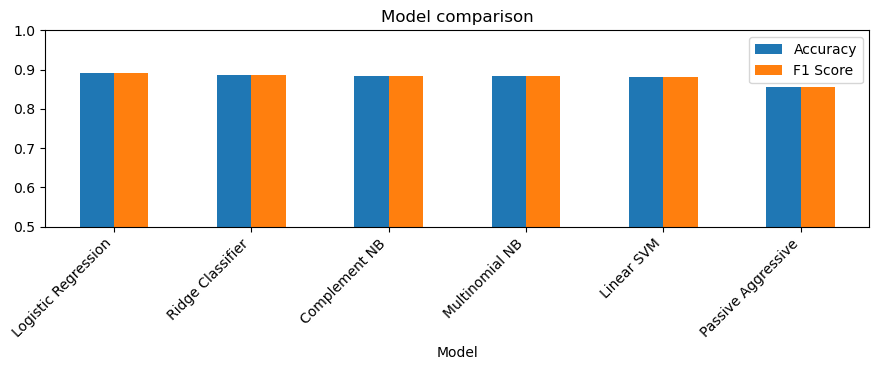

In [6]:
fig,ax=plt.subplots(figsize=(9,3.8))
res_df.set_index('Model')[['Accuracy','F1 Score']].plot(kind='bar',ax=ax); ax.set_title('Model comparison')
ax.set_ylim(min(0.5,res_df['F1 Score'].min()-0.05),1.0)
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

## Confusion matrix (best model)

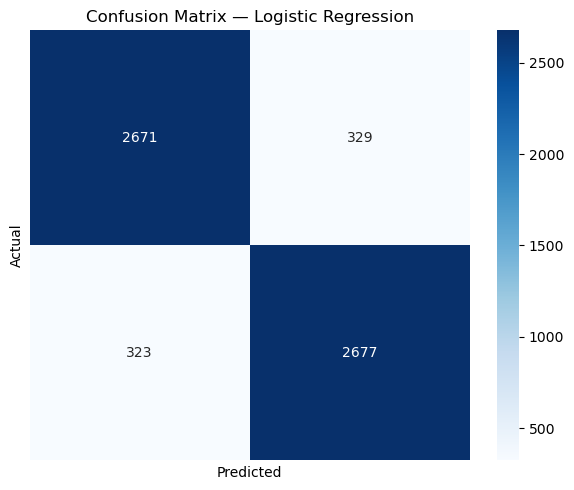

In [7]:
best_name=res_df.iloc[0]['Model']
best=utils.get_models()[best_name]
best.fit(Xtrain,y_train)
pred=best.predict(Xtest)
fig,ax=plt.subplots(figsize=(6,5))
utils.plot_confusion_matrix(y_test,pred,best_name,labels='',ax=ax)
plt.tight_layout()
plt.show()

## Tune Logistic Regression (C)

In [9]:
gs=GridSearchCV(LogisticRegression(max_iter=1000),{'C':[0.1,1,10]},cv=3,scoring='f1_weighted',n_jobs=-1)
gs.fit(Xtrain,y_train)
from sklearn.metrics import f1_score,accuracy_score
tp=gs.best_estimator_.predict(Xtest)
print('best C:',gs.best_params_['C'])
print('tuned accuracy: %.4f'%accuracy_score(y_test,tp))
print('tuned weighted F1: %.4f'%f1_score(y_test,tp,average='weighted'))

best C: 1
tuned accuracy: 0.8913
tuned weighted F1: 0.8913


## Prediction example

In [10]:
sample=X_test.iloc[0]
print('text :',str(sample)[:160])
print('true :',y_test.iloc[0])
print('pred :',best.predict(vec.transform([sample]))[0])

text : defective return ordered item aware could returned defective item arrived timely would operate later found product nonreturnable dissatisfied purchase
true : negative
pred : negative


## Results

All figures produced by executing `03_model_building.ipynb` — not assumed. 80/20 stratified
split (balanced classes, so accuracy ≈ F1).

| Model | Accuracy | F1 (weighted) |
|---|---|---|
| **Logistic Regression** | **0.8910** | **0.8910** |
| Multinomial NB | 0.8837 | 0.8837 |
| Complement NB | 0.8837 | 0.8837 |
| Ridge Classifier | 0.8837 | 0.8837 |
| Linear SVM | 0.8793 | 0.8793 |
| Passive Aggressive | 0.8553 | 0.8553 |

Tuned Logistic Regression (C=1): **accuracy 0.891, F1 0.891**.

## Key Findings

- **Logistic Regression on TF-IDF reaches 89% accuracy** on balanced positive/negative reviews —
  a strong, fast baseline with no deep learning.
- **The models cluster tightly (0.86–0.89 F1)** — sentiment is largely carried by individual
  cue words ("great", "terrible", "refund"), which every linear/NB model picks up.
- **The gap to ~95%+ needs context the bag-of-words misses** — negation, sarcasm, and long-range
  dependencies ("not what I expected") cap a TF-IDF model; that's where transformers would help.
- **Tuning barely moves the needle** — TF-IDF + linear models are near their ceiling here;
  better features (n-grams, embeddings) matter more than hyperparameters.